# Calling the Material Finder API

This notebook calls our model server on Render, the same way the Cloudflare app does, and prints the answers.

- **Server:** https://team7-material-finder.onrender.com
- **`/predict`**: a photo → ranked materials, 5 clean swatches, 5 similar photos, unusual score
- **`/similar`**: a gallery item (photo or swatch) → the most similar photos and swatches

Only the Python standard library is used for the calls (`urllib`, `json`, `base64`); `matplotlib` and `Pillow` only draw the result.
Gradio's HTTP API has two steps: `POST /gradio_api/call/<api>` starts a job and returns an `event_id`, then
`GET /gradio_api/call/<api>/<event_id>` returns `event: complete` and `data: [result]`.

> The free server sleeps after 15 minutes without requests. The first call wakes it up, which takes about a minute.

In [1]:
import base64
import io
import json
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

URL = "https://team7-material-finder.onrender.com"
EXAMPLES = Path("examples")   # run from the 02_model_server folder


def call_api(api, data, timeout=120):
    """Call one Gradio API endpoint in two steps and return its result (raises on an error event)."""
    start = urllib.request.Request(f"{URL}/gradio_api/call/{api}", data=json.dumps({"data": data}).encode(),
                                   headers={"Content-Type": "application/json"}, method="POST")
    with urllib.request.urlopen(start, timeout=timeout) as response:
        event_id = json.load(response)["event_id"]
    with urllib.request.urlopen(f"{URL}/gradio_api/call/{api}/{event_id}", timeout=timeout) as response:
        text = response.read().decode()
    if "event: complete" not in text:
        raise RuntimeError(text.strip()[:300])
    return json.loads(text.split("event: complete")[1].split("data:", 1)[1].strip())[0]


def b64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()

## 1. Wake the server

If it was asleep this takes about a minute; if it is awake, well under a second.

In [2]:
t = time.time()
with urllib.request.urlopen(f"{URL}/gradio_api/info", timeout=180) as response:
    endpoints = list(json.load(response)["named_endpoints"])
print(f"server answered in {time.time() - t:.1f} s, endpoints: {endpoints}")

server answered in 0.7 s, endpoints: ['/predict', '/similar']


## 2. `/predict`: one photo

The input is a base64-encoded JPEG or PNG. The server uses the middle of the photo (centre square, middle half, 224 px).

In [3]:
t = time.time()
result = call_api("predict", [b64(EXAMPLES / "brick.jpg")])
print(f"answer in {time.time() - t:.1f} s\n")

print("Materials:", " · ".join(f"{m['name']} {m['share']:.0%}" for m in result["materials"]))
print(f"Unusual score {result['unusual_score']:.3f} (threshold {result['threshold']:.3f}) -> is_unusual = {result['is_unusual']}")
print("\n5 clean swatches (CC0):")
for s in result["swatches"]:
    print(f"  {s['rank']}. {s['name']:<28} {s['material']:<10} {s['library']:<11} distance {s['distance']:.3f}")
print("\n5 similar photos (MINC-2500):")
for m in result["matches"]:
    print(f"  {m['rank']}. photo {m['id']:<6} {m['material']:<14} distance {m['distance']:.3f}")

answer in 1.5 s

Materials: brick 100%
Unusual score 0.364 (threshold 0.734) -> is_unusual = False

5 clean swatches (CC0):
  1. acg_bricks_074               brick      ambientCG   distance 0.276
  2. acg_paving_stones_124        paving     ambientCG   distance 0.285
  3. acg_bricks_010               brick      ambientCG   distance 0.286
  4. acg_bricks_052               brick      ambientCG   distance 0.294
  5. acg_bricks_051               brick      ambientCG   distance 0.303

5 similar photos (MINC-2500):
  1. photo 952    brick          distance 0.115
  2. photo 414    brick          distance 0.131
  3. photo 916    brick          distance 0.133
  4. photo 834    brick          distance 0.135
  5. photo 1479   brick          distance 0.144


The full JSON answer (what the app receives). Each item has a `thumb_url` on Hugging Face that a web page can show directly:

In [4]:
short = {**result, "matches": result["matches"][:1] + ["… 4 more"], "swatches": result["swatches"][:1] + ["… 4 more"]}
print(json.dumps(short, indent=2))

{
  "material_guess": "brick",
  "confidence": 1.0,
  "materials": [
    {
      "name": "brick",
      "share": 1.0
    }
  ],
  "matches": [
    {
      "source": "photo",
      "id": 952,
      "material": "brick",
      "thumb_url": "https://huggingface.co/iaac-maai/hackathon-team7-material-finder-ae/resolve/cbe7297f47bef9d54a9ed8c2889c3e6e35be41c5/gallery_thumbs/00183.jpg",
      "distance": 0.1152,
      "rank": 1
    },
    "\u2026 4 more"
  ],
  "swatches": [
    {
      "source": "swatch",
      "id": 56,
      "material": "brick",
      "thumb_url": "https://huggingface.co/iaac-maai/hackathon-team7-material-finder-ae/resolve/cbe7297f47bef9d54a9ed8c2889c3e6e35be41c5/swatch_thumbs/00056.jpg",
      "name": "acg_bricks_074",
      "category": "terracotta",
      "library": "ambientCG",
      "link": "https://www.ambientcg.com/view?id=Bricks074",
      "colour": "orange",
      "sphere_url": "https://huggingface.co/iaac-maai/hackathon-team7-material-finder-ae/resolve/cbe7297f47be

Drawn: the photo we sent, then the swatches and photos the server found.

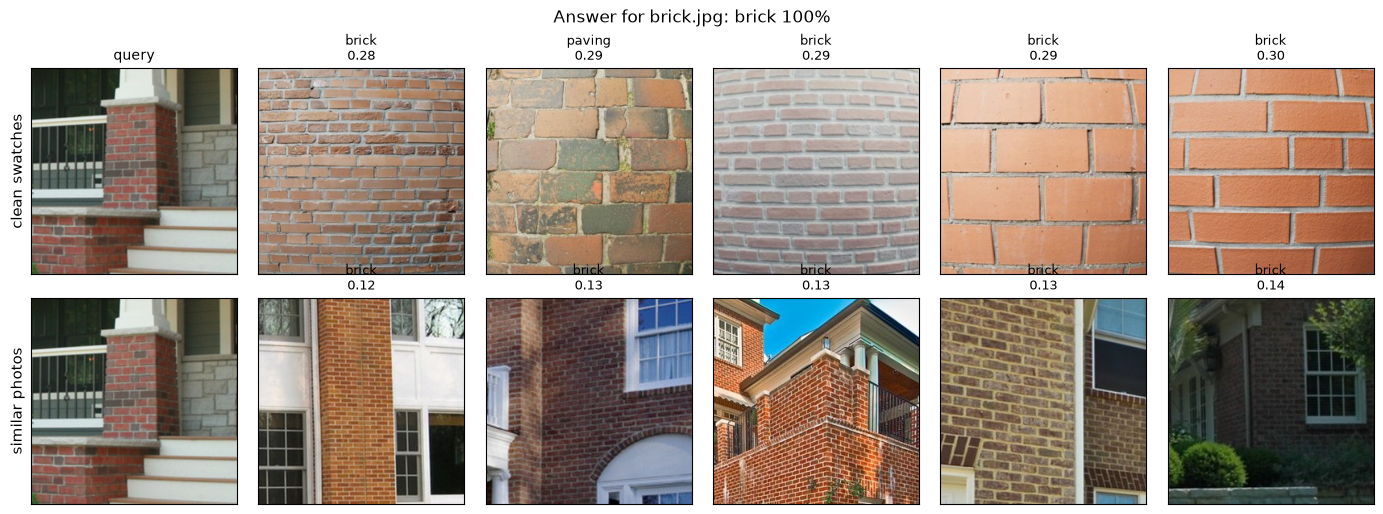

In [5]:
def load(url):
    with urllib.request.urlopen(url, timeout=60) as response:
        return Image.open(io.BytesIO(response.read())).convert("RGB")


fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
for row, (title, items) in enumerate([("clean swatches", result["swatches"]), ("similar photos", result["matches"])]):
    ax = axes[row, 0]
    ax.imshow(Image.open(EXAMPLES / "brick.jpg"))
    ax.set_title("query" if row == 0 else "", fontsize=10)
    ax.set_ylabel(title, fontsize=11)
    for col, item in enumerate(items, start=1):
        axes[row, col].imshow(load(item["thumb_url"]))
        axes[row, col].set_title(f"{item['material']}\n{item['distance']:.2f}", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Answer for brick.jpg: " + " · ".join(f"{m['name']} {m['share']:.0%}" for m in result["materials"]))
plt.tight_layout()
plt.show()

## 3. All four example photos

In [6]:
print(f"{'photo':<10} {'answer':<36} {'closest swatch':<28} unusual")
for path in sorted(EXAMPLES.glob("*.jpg")):
    r = call_api("predict", [b64(path)])
    answer = " · ".join(f"{m['name']} {m['share']:.0%}" for m in r["materials"])
    print(f"{path.stem:<10} {answer:<36} {r['swatches'][0]['name']:<28} {r['is_unusual']}")

photo      answer                               closest swatch               unusual


brick      brick 100%                           acg_bricks_074               False


carpet     wood 60% · metal 20% · carpet 20%    acg_wood_018                 False


tile       tile 100%                            acg_tiles_109                False


wood       painted 100%                         acg_concrete_042_b           False


## 4. `/similar`: more like one gallery item

No upload: the server uses the stored code of a swatch or photo. Arguments: `source` (`"photo"` or `"swatch"`), `id`, `k` (1–40).

In [7]:
first_swatch = result["swatches"][0]
similar = call_api("similar", ["swatch", first_swatch["id"], 6])
print(f"More like swatch {similar['item']['id']} ({similar['item']['name']}, {similar['item']['material']}):")
print("  swatches:", ", ".join(f"{s['name']} ({s['material']})" for s in similar["swatches"]))
print("  photos:  ", ", ".join(f"{p['material']}" for p in similar["photos"]))

More like swatch 56 (acg_bricks_074, brick):
  swatches: acg_bricks_010 (brick), acg_bricks_007 (brick), acg_paving_stones_092 (paving), th_brick_004 (brick), acg_paving_stones_043 (paving), acg_bricks_073_a (brick)
  photos:   brick, brick, brick, brick, brick, brick


## 5. A bad input gives a clear error, not a crash

In [8]:
try:
    call_api("predict", ["this is not an image"])
except RuntimeError as error:
    print("The server refused it:", error)

The server refused it: event: error
data: {"error": "The data is not an image (use JPEG or PNG).", "duration": 10, "visible": true, "title": "Error"}
